---
title: "L5-04 · Tensor products and entanglement"
short_title: "Tensor products and entanglement"
subtitle: "A two-qubit pure state is a 2 x 2 matrix of amplitudes; it is a product state exactly when that matrix has rank one, and an entangled state shows correlations in several bases at once that no coin-flip mixture of product states can reproduce."
description: "Decide whether a two-qubit pure state is entangled from its coefficient matrix, and distinguish entanglement from classical correlation with measurements in two bases."
tags: [level-5, coursebook]
---

(lesson-l5-04)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 105 minutes  
**Big idea.** A two-qubit pure state is a 2 x 2 matrix of amplitudes; it is a product state exactly when that matrix has rank one, and an entangled state shows correlations in several bases at once that no coin-flip mixture of product states can reproduce.  
**Before this lesson.** [L5-01](#lesson-l5-01), [L5-02](#lesson-l5-02), [L3-04](#lesson-l3-04)  
**Lab.** [Entanglement and Bell tests](../../labs/06-entanglement-bell.ipynb)
:::

## What you will be able to do

- Build two-qubit states and operators with the tensor (Kronecker) product in the stated basis order, and write the coefficient matrix $C_{ij} = \langle ij|\psi\rangle$.
- Decide whether a pure two-qubit state is a product state using $\det C$ or the Schmidt rank, and compute its Schmidt coefficients and entanglement entropy from a singular value decomposition.
- Explain with numbers why perfect correlation in one basis does not prove entanglement, and use the witness $\langle XX\rangle + \langle ZZ\rangle \le 1$ to show that $|\Phi^+\rangle$ is entangled.

## Why this matters

A referee hands two sealed boxes to two labs far apart. Each lab measures its qubit in the computational basis, and over thousands of rounds the results always match: 00 or 11, never 01 or 10. Is this entanglement? Not necessarily. The referee could simply flip a coin each round and put both qubits in $|0\rangle$ or both in $|1\rangle$. That preparation gives exactly the same table of results, and nothing quantum happened.

Entanglement is the resource behind teleportation, Bell tests, and quantum error correction, so it is worth knowing exactly what it is and how to tell it apart from ordinary shared randomness. This lesson gives the algebra (the tensor product and the coefficient matrix, whose rank decides the question for pure states) and the operational test (a second measurement basis, and an inequality that every coin-flip mixture of product states obeys).

:::{dropdown} Key terms

**Tensor product**
: The rule that combines the state spaces of two systems: $|a\rangle \otimes |b\rangle$, written $|ab\rangle$, with components $a_i b_j$. Two qubits live in $\mathbb{C}^2 \otimes \mathbb{C}^2 = \mathbb{C}^4$.

**Product state**
: A joint pure state of the form $|a\rangle \otimes |b\rangle$: each part has its own state.

**Entangled pure state**
: A joint pure state that cannot be written as $|a\rangle \otimes |b\rangle$ for any single-system states.

**Coefficient matrix**
: For $|\psi\rangle = \sum_{i,j} C_{ij}|ij\rangle$, the matrix $C$ with rows indexed by A and columns by B.

**Schmidt decomposition**
: The form $|\psi\rangle = \sum_k s_k |u_k\rangle|v_k\rangle$ with orthonormal $\{|u_k\rangle\}$, $\{|v_k\rangle\}$ and $s_k > 0$; the number of terms is the Schmidt rank.

**Coin-flip mixture**
: A preparation that picks one of several states at random with known probabilities; its outcome probabilities are the averages of the Born probabilities.

**Entanglement witness**
: A quantity with a bound that every unentangled preparation obeys, so a measured violation certifies entanglement (under the stated measurement model).

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_04 as _lessonfigs

## Joint systems and the tensor product

Two qubits A and B have four joint basis states. Throughout this lesson we fix one convention and use it everywhere: $|ab\rangle = |a\rangle \otimes |b\rangle$ with **A as the left factor**, and the basis order $|00\rangle, |01\rangle, |10\rangle, |11\rangle$ (A is the more significant bit). This is the order of `numpy.kron(A, B)` and of [L3-04](#lesson-l3-04). Some software lists qubits the other way round, so check the convention before comparing numbers.

:::{prf:definition} Tensor product of vectors and operators
:label: def-l5-04-tensor
For $|a\rangle = (a_0, a_1)^T$ and $|b\rangle = (b_0, b_1)^T$, $\;|a\rangle \otimes |b\rangle = (a_0 b_0,\ a_0 b_1,\ a_1 b_0,\ a_1 b_1)^T$. For single-qubit operators, $(M \otimes N)(|a\rangle \otimes |b\rangle) = M|a\rangle \otimes N|b\rangle$, extended linearly; its matrix is the Kronecker product, the $4 \times 4$ block matrix $\begin{pmatrix} m_{00}N & m_{01}N \\ m_{10}N & m_{11}N \end{pmatrix}$.
:::

Every two-qubit state is a combination of the four basis states, and it is convenient to arrange its four amplitudes as a $2 \times 2$ matrix with one row for each value of A and one column for each value of B [@nielsenchuang; @ibm]:

$$
|\psi\rangle = \sum_{i,j \in \{0,1\}} C_{ij}\,|ij\rangle, \qquad C_{ij} = \langle ij|\psi\rangle, \qquad \sum_{i,j} |C_{ij}|^2 = 1
$$ (eq-l5-04-coeff)

:::{prf:definition} Product and entangled pure states
:label: def-l5-04-entangled
A pure state $|\psi\rangle$ of AB is a **product state** if $|\psi\rangle = |a\rangle \otimes |b\rangle$ for some single-qubit states $|a\rangle$, $|b\rangle$. Otherwise it is **entangled**.
:::

:::{prf:example} A sum that is still a product
:label: ex-l5-04-plus0
$|+\rangle|0\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle) \otimes |0\rangle = \tfrac{1}{\sqrt2}(|00\rangle + |10\rangle)$, so $C = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & 0\\ 1 & 0\end{pmatrix}$. Being written with two terms does not make a state entangled; $\tfrac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle) = |+\rangle|+\rangle$ has four terms and is a product.
:::

## Product or entangled? The rank of C

For a product state the amplitudes factor: $C_{ij} = a_i b_j$, so $C = |a\rangle\,(b_0, b_1)$ is a column times a row. Such a matrix has rank one: its two rows are multiples of the same row. That observation is the whole test.

:::{prf:theorem} Product test for two-qubit pure states
:label: thm-l5-04-rank
For a two-qubit pure state with coefficient matrix $C$, the following are equivalent: (i) $|\psi\rangle$ is a product state; (ii) $\operatorname{rank} C = 1$; (iii) $\det C = C_{00}C_{11} - C_{01}C_{10} = 0$.
:::

:::{prf:proof}
(i) $\Rightarrow$ (ii): if $|\psi\rangle = |a\rangle|b\rangle$ then $C_{ij} = a_i b_j$, so $C = a\,b^T$ is an outer product of two nonzero vectors and has rank 1. (ii) $\Rightarrow$ (i): a rank-1 matrix can be written $C = a\,b^T$ with nonzero column vectors $a$, $b$; rescale so that $\|a\| = 1$, and then $\sum|C_{ij}|^2 = \|a\|^2\|b\|^2 = 1$ forces $\|b\| = 1$, so $|\psi\rangle = |a\rangle \otimes |b\rangle$ with $|a\rangle = \sum_i a_i|i\rangle$ and $|b\rangle = \sum_j b_j |j\rangle$. (ii) $\Leftrightarrow$ (iii): $C \neq 0$ because the state is normalized, so its rank is 1 or 2, and a $2 \times 2$ matrix has rank 2 exactly when $\det C \neq 0$.
:::

Picture $C$ as a linear map of the plane (for real amplitudes). It sends the unit circle to an ellipse whose semi-axes are the singular values $s_1 \ge s_2 \ge 0$ of $C$. A product state squashes the circle flat onto a segment ($s_2 = 0$). For the family $\cos\theta\,|00\rangle + \sin\theta\,|11\rangle$ we have $C = \operatorname{diag}(\cos\theta, \sin\theta)$ and $\det C = \cos\theta\,\sin\theta$, so the ellipse opens as $\theta$ grows and becomes a circle of radius $1/\sqrt2$ at $\theta = \pi/4$, the Bell state $|\Phi^+\rangle$.

:::{figure} ../../_static/animations/l5_04_schmidt_ellipse.mp4
:alt: The unit circle is mapped by the coefficient matrix of the product state |+>|0> onto a line segment; then for cos(theta)|00> + sin(theta)|11> it becomes an ellipse that opens into a circle, while a graph of the entanglement entropy rises to 1.
:width: 100%

The coefficient matrix as a map: rank 1 flattens the circle (a product state); the Bell state keeps it round, with $s_1 = s_2 = 1/\sqrt{2}$.
:::

:::{dropdown} What the animation shows
The scene writes $|\psi\rangle = \sum_{i,j} C_{ij}|ij\rangle$ and draws the unit circle. For $|+\rangle|0\rangle$, with $C = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & 0\\ 1 & 0\end{pmatrix}$, the circle is transformed by $C$ into a diagonal segment: $\det C = 0$, rank 1, singular values $s_1 = 1$ and $s_2 = 0$, a product state with one direction for A and one for B. Then the state $\cos\theta\,|00\rangle + \sin\theta\,|11\rangle$ is shown with $C = \operatorname{diag}(\cos\theta, \sin\theta)$ and $\det C = \cos\theta\,\sin\theta$. As $\theta$ sweeps from 0 to $\pi/4$ the image is an ellipse with semi-axes $s_1 = \cos\theta$ and $s_2 = \sin\theta$ (live readouts), and a graph traces the entanglement entropy $E$ from 0 up to 1. At $\theta = \pi/4$ the state is $|\Phi^+\rangle$, the ellipse is a circle, $s_1 = s_2 = 1/\sqrt{2}$, and $E = 1$.
:::

:::{prf:theorem} Schmidt decomposition
:label: thm-l5-04-schmidt
Every pure state of AB can be written $|\psi\rangle = \sum_{k} s_k\,|u_k\rangle|v_k\rangle$ with orthonormal sets $\{|u_k\rangle\}$ in A, $\{|v_k\rangle\}$ in B, and real $s_k > 0$ with $\sum_k s_k^2 = 1$. The $s_k$ (the Schmidt coefficients) are the nonzero singular values of $C$ and are unique; their number is the Schmidt rank. A pure state is a product state exactly when its Schmidt rank is 1 [@nielsenchuang].
:::

:::{prf:proof}
Take the singular value decomposition $C = U\Sigma V^\dagger$ with $U$, $V$ unitary and $\Sigma = \operatorname{diag}(s_1, s_2)$, $s_1 \ge s_2 \ge 0$. Then $C_{ij} = \sum_k U_{ik}\,s_k\,(V^\dagger)_{kj}$, and substituting into [](#eq-l5-04-coeff) gives $|\psi\rangle = \sum_k s_k \big(\sum_i U_{ik}|i\rangle\big)\big(\sum_j (V^\dagger)_{kj}|j\rangle\big)$. Define $|u_k\rangle = \sum_i U_{ik}|i\rangle$ (column $k$ of $U$) and $|v_k\rangle = \sum_j (V^\dagger)_{kj}|j\rangle$ (row $k$ of $V^\dagger$). Columns of a unitary are orthonormal, and so are rows, so both sets are orthonormal. Normalization gives $\sum_k s_k^2 = \sum_{ij}|C_{ij}|^2 = 1$. Drop the terms with $s_k = 0$. Singular values of a matrix are unique, so the $s_k$ are. The last claim is Theorem [](#thm-l5-04-rank), since the rank of $C$ is the number of nonzero singular values.
:::

$$
s_1 s_2 = |\det C|, \qquad s_{1,2}^2 = \tfrac12\Big(1 \pm \sqrt{1 - 4|\det C|^2}\Big), \qquad E = -\sum_k s_k^2 \log_2 s_k^2
$$ (eq-l5-04-schmidt)

The first identity holds because $|\det U| = |\det V| = 1$, so $|\det C| = \det\Sigma = s_1 s_2$; together with $s_1^2 + s_2^2 = 1$ it gives the second. So for two qubits the single number $|\det C|$ fixes the Schmidt coefficients. The **entanglement entropy** $E$ (in bits, logs base 2) is the Shannon entropy of the squared Schmidt coefficients: $E = 0$ for a product state and $E = 1$ for $|\Phi^+\rangle$, where $\det C = 1/2$ and $s_1 = s_2 = 1/\sqrt{2}$. Twice $|\det C|$ is called the concurrence of the pure state; it also runs from 0 (product) to 1 (maximally entangled).


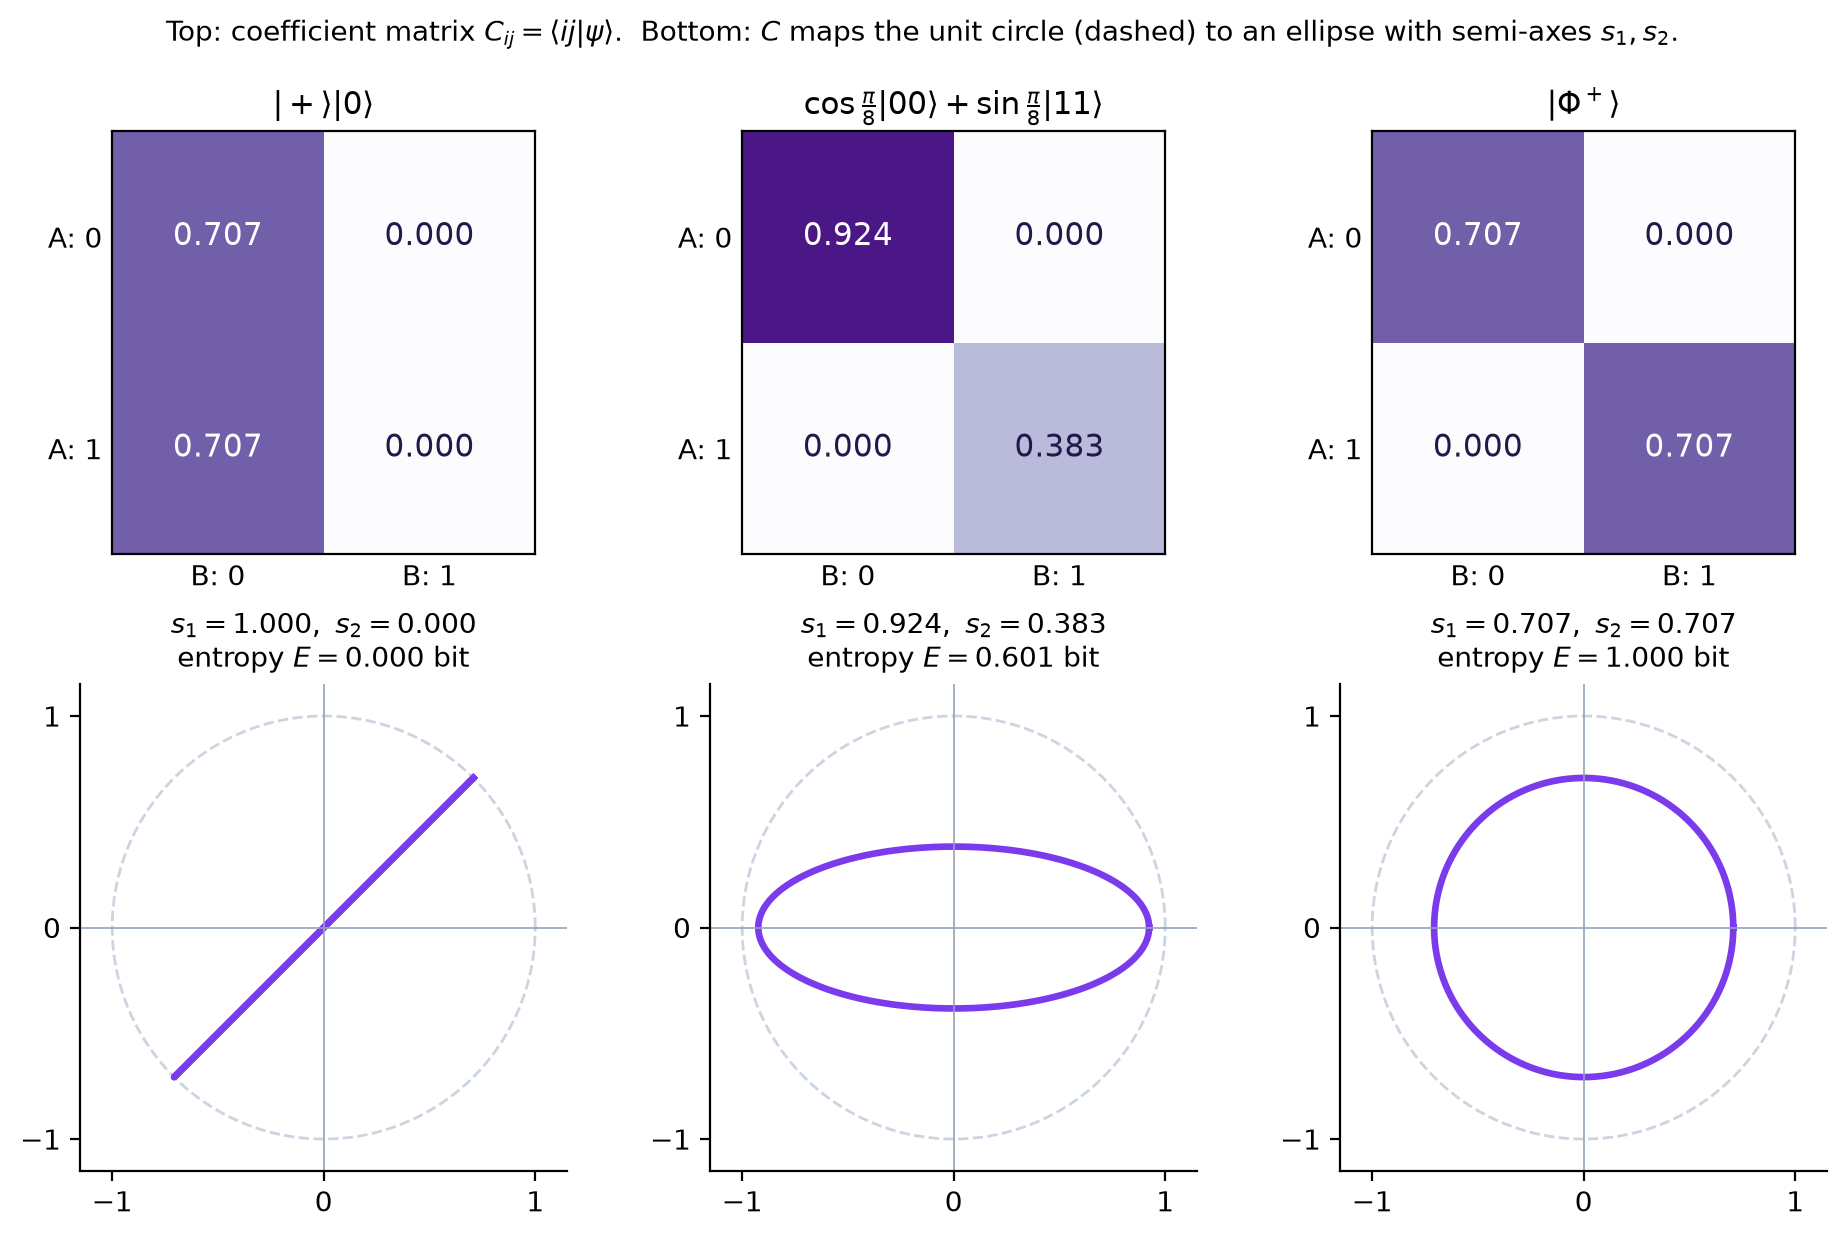

In [2]:
_show_mpl(_lessonfigs.coefficient_matrices())

*Three states, three coefficient matrices. A product state ($|+\rangle|0\rangle$) maps the circle to a segment; $\cos\frac{\pi}{8}|00\rangle + \sin\frac{\pi}{8}|11\rangle$ to an ellipse with $s_1 = 0.924$, $s_2 = 0.383$ and $E = 0.601$ bit; $|\Phi^+\rangle$ to a circle of radius $1/\sqrt2$ with $E = 1$.*

:::{prf:remark} Conjugation in the B vectors
:label: rem-l5-04-vh
In software, `U, s, Vh = numpy.linalg.svd(C)` returns $V^\dagger$ as `Vh`. The B vectors are the **rows** of `Vh`, which are the complex conjugates of the columns of $V$. For real amplitudes the difference is invisible; for complex amplitudes using the columns of $V$ gives a wrong reconstruction. The code below checks this on a complex state.
:::

## Making entanglement: H then CNOT

Take CNOT with control A and target B: $\mathrm{CNOT}\,|a\,b\rangle = |a,\ b\oplus a\rangle$, where $\oplus$ is addition mod 2. In the basis order above its matrix swaps the last two amplitudes. Start from $|00\rangle$, apply $H$ to A, then CNOT:

$$
|00\rangle \xrightarrow{\;H \otimes I\;} \tfrac{1}{\sqrt2}(|00\rangle + |10\rangle) = |+\rangle|0\rangle \xrightarrow{\;\mathrm{CNOT}\;} \tfrac{1}{\sqrt2}(|00\rangle + |11\rangle) = |\Phi^+\rangle
$$ (eq-l5-04-bell)

:::{figure} ../../_static/animations/l5_04_cnot_entangles.mp4
:alt: A two-qubit circuit with H on qubit A and a CNOT; amplitude bars over 00, 01, 10, 11 change from one bar to two bars, then the bar at 10 moves to 11; the coefficient matrix determinant changes from 0 to 1/2.
:width: 100%

H makes a superposition on A but leaves a product state; CNOT moves the $|10\rangle$ amplitude to $|11\rangle$ and $\det C$ jumps from 0 to $1/2$.
:::

:::{dropdown} What the animation shows
A circuit shows qubits A and B starting in $|0\rangle$, an H gate on A, and a CNOT with control A. A dashed time slice moves through the circuit. At the start the amplitude bars show a single bar at 00, $C = \begin{pmatrix}1 & 0\\ 0 & 0\end{pmatrix}$ and $\det C = 0$. After H the state is $\tfrac{1}{\sqrt2}(|00\rangle + |10\rangle) = |+\rangle|0\rangle$: two bars of height $1/\sqrt2$ at 00 and 10, $C = \tfrac{1}{\sqrt2}\begin{pmatrix}1 & 0\\ 1 & 0\end{pmatrix}$, still $\det C = 0$. The rule $\mathrm{CNOT}\,|a\,b\rangle = |a,\ b\oplus a\rangle$ appears; the bar at 10 slides to 11, the state becomes $\tfrac{1}{\sqrt2}(|00\rangle + |11\rangle)$, $C = \tfrac{1}{\sqrt2}I$, and $\det C = 1/2$: no way to write the state as an A state times a B state.
:::

:::{prf:proposition} Local gates cannot create entanglement
:label: prop-l5-04-local
For single-qubit unitaries $U$ on A and $V$ on B, the state $(U \otimes V)|\psi\rangle$ has coefficient matrix $U C V^T$, so it has the same Schmidt coefficients, the same $|\det C|$, and the same entanglement entropy as $|\psi\rangle$.
:::

:::{prf:proof}
$(U \otimes V)\sum_{ij} C_{ij}|i\rangle|j\rangle = \sum_{ij} C_{ij}\,U|i\rangle\,V|j\rangle = \sum_{kl}\big(\sum_{ij} U_{ki}C_{ij}V_{lj}\big)|kl\rangle$, and $\sum_{ij} U_{ki}C_{ij}V_{lj} = (U C V^T)_{kl}$. Multiplying by unitaries on either side does not change singular values ($V^T$ is unitary when $V$ is), and $|\det(UCV^T)| = |\det U|\,|\det C|\,|\det V| = |\det C|$.
:::

So the jump of $\det C$ from 0 to $1/2$ in the animation must come from CNOT, a genuinely two-qubit gate. The Hadamard step only changes the local basis of A.

## Correlation is not entanglement

```{mermaid}
graph LR
  S1[Bell source] --> M{Both labs pick Z or X}
  S2[Coin-flip source: 00 or 11] --> M
  M --> T1[Z basis: both always agree]
  M --> T2[X basis: only Bell always agrees]
```

*The two sources give the same Z-basis table. A second basis separates them.*

The coin-flip source of the motivation prepares $|00\rangle$ with probability $1/2$ and $|11\rangle$ with probability $1/2$. Density operators, which describe such mixtures compactly, arrive in [L5-05](#lesson-l5-05); for now we only need the rule that outcome probabilities of a coin-flip mixture are the averages of the Born probabilities:

$$
P_{\text{mix}}(a, b) = \tfrac12\,|\langle ab|00\rangle|^2 + \tfrac12\,|\langle ab|11\rangle|^2
$$ (eq-l5-04-mix)

In the Z basis both sources give 00 and 11 with probability $1/2$ each. In the X basis, with $|\pm\rangle = (|0\rangle \pm |1\rangle)/\sqrt2$, the Bell state rewrites as $|\Phi^+\rangle = \tfrac{1}{\sqrt2}(|{+}{+}\rangle + |{-}{-}\rangle)$, so the signs still agree with probability 1. The coin-flip source gives $|00\rangle$ or $|11\rangle$, and each $|0\rangle$ or $|1\rangle$ shows $+$ or $-$ with probability $1/2$ independently, so all four X-basis pairs have probability $1/4$ and the signs agree only half the time.

:::{figure} ../../_static/animations/l5_04_bell_vs_mixture.mp4
:alt: Four histograms fill up shot by shot: the Bell state and the coin-flip mixture both show only 00 and 11 in the Z basis; in the X basis the Bell state shows only ++ and --, the mixture shows all four outcomes about equally.
:width: 100%

Histograms that sharpen as shots accumulate: identical in Z, different in X. Then the witness $\langle XX\rangle + \langle ZZ\rangle \le 1$ for every coin-flip mixture of product states.
:::

:::{dropdown} What the animation shows
Two columns, the Bell state $|\Phi^+\rangle$ and the coin-flip source ($|00\rangle$ or $|11\rangle$), each with a Z-basis and an X-basis histogram. A shot counter runs to 400 and the bars and the fraction of agreeing outcomes update live. In the simulated run (400 shots per setting, seed 5) the Bell state gave 209 times 00 and 191 times 11 in Z, and 220 times ++ and 180 times $--$ in X; the coin-flip source gave 200 and 200 in Z, and 88, 105, 107, 100 for ++, +$-$, $-$+, $--$ in X, so its X-basis agreement fraction was 0.47. The exact values then appear: $P(\text{agree}) = 1$ for both sources in Z, $P(\text{agree}) = 1$ for the Bell state in X, and $P(\text{agree}) = 1/2$ for the coin-flip source in X. Finally the screen states that any coin-flip mixture of product states obeys $\langle XX\rangle + \langle ZZ\rangle \le 1$, while $|\Phi^+\rangle$ gives $1 + 1 = 2$ and the coin-flip source $0 + 1 = 1$: the Bell state is entangled, and one basis alone could not show it.
:::

:::{prf:theorem} A two-setting entanglement witness
:label: thm-l5-04-witness
Let $\langle XX\rangle$ denote the expectation of $X \otimes X$ (the average product of the two $\pm 1$ results when both labs measure X), and similarly $\langle ZZ\rangle$. Every coin-flip mixture of product states, $\{p_k, |a_k\rangle|b_k\rangle\}$, satisfies $\langle XX\rangle + \langle ZZ\rangle \le 1$. The Bell state $|\Phi^+\rangle$ gives $\langle XX\rangle + \langle ZZ\rangle = 2$.
:::

:::{prf:proof}
For one product state $|a\rangle|b\rangle$, the expectation factorizes: $\langle a|\langle b|\,X \otimes X\,|a\rangle|b\rangle = \langle a|X|a\rangle\langle b|X|b\rangle = x_a x_b$, where $(x, y, z)$ is the Bloch vector of [L5-01](#lesson-l5-01), with $\langle X\rangle = x$ and $\langle Z\rangle = z$. Likewise $\langle ZZ\rangle = z_a z_b$. By the Cauchy-Schwarz inequality, $x_a x_b + z_a z_b \le \sqrt{x_a^2 + z_a^2}\,\sqrt{x_b^2 + z_b^2} \le 1$, because Bloch vectors of pure states have length 1. A coin-flip mixture averages these values with weights $p_k \ge 0$ that sum to 1, and an average of numbers at most 1 is at most 1. For the Bell state, $X \otimes X$ and $Z \otimes Z$ both leave $|\Phi^+\rangle$ unchanged, so both expectations equal 1.
:::


In [3]:
_show(_lessonfigs.correlation_explorer())

**Explore.** Both labs measure along the same direction $\cos\theta\,Z + \sin\theta\,X$. Drag $\theta$: the Bell state keeps $E(\theta) = 1$; the coin-flip mixture gives $E(\theta) = \cos^2\theta$.

:::{dropdown} What the figure shows
The first panel shows the four joint outcome probabilities (++, +$-$, $-$+, $--$) for the Bell state and for the coin-flip mixture at the chosen angle. The second panel plots the correlation $E(\theta) = P(\text{agree}) - P(\text{differ})$ against $\theta$ from $0^\circ$ to $180^\circ$: a flat line at 1 for the Bell state and the curve $\cos^2\theta$ for the mixture, which drops to 0 at $90^\circ$ (the X basis) and returns to 1 at $180^\circ$.
:::

The flat line has a reason: $|\Phi^+\rangle$ is unchanged by $O \otimes O$ for every real rotation $O$, so it is perfectly correlated along every direction in the X-Z plane. It is **not** correlated along every direction: $Y \otimes Y\,|\Phi^+\rangle = -|\Phi^+\rangle$, so $\langle YY\rangle = -1$ and Y results always disagree. For the mixture, each branch gives $\langle A\rangle_a\langle A\rangle_b = (\pm\cos\theta)^2$, hence $E = \cos^2\theta$.

:::{prf:proposition} No signaling
:label: prop-l5-04-nosignal
Whatever the joint state, the probability of each outcome in lab A does not depend on which basis lab B chooses to measure.
:::

:::{prf:proof}
Let A measure with projectors $\{\Pi_a\}$ and B with any projectors $\{\Pi'_b\}$, which satisfy $\sum_b \Pi'_b = I$. Then $P(a) = \sum_b \langle\psi|\Pi_a \otimes \Pi'_b|\psi\rangle = \langle\psi|\Pi_a \otimes I|\psi\rangle$, which contains no trace of B's choice. For $|\Phi^+\rangle$ every local outcome has probability $1/2$ in every basis; the structure lives only in the joint table.
:::

:::{important} What the second basis buys
One correlation table can always be produced by a coin-flip mixture of product states. Entanglement is a property of the joint state, and certifying it needs measurements in at least two bases (here X and Z) plus a trusted description of what those measurements are. Bell tests in [L5-08](#lesson-l5-08) drop the trust in the devices at the price of stronger assumptions about locality and setting choices [@bell].
:::

## Compute it

Build states with `np.kron` (A on the left), read off the coefficient matrix, test $\det C$, and get the Schmidt decomposition from the SVD. The reconstruction check uses a state with complex amplitudes so that the rows-of-`Vh` rule is really tested.


In [4]:
import numpy as np

k0, k1 = np.array([1, 0], dtype=complex), np.array([0, 1], dtype=complex)
plus = (k0 + k1) / np.sqrt(2)
bell = (np.kron(k0, k0) + np.kron(k1, k1)) / np.sqrt(2)
prod = np.kron(plus, k0)                      # |+>|0>, basis order 00, 01, 10, 11

for name, psi in [('|+>|0>', prod), ('Phi+', bell)]:
    C = psi.reshape(2, 2)                      # C[i, j] = <ij|psi>, A is the row index
    s = np.linalg.svd(C, compute_uv=False)
    p = s[s > 1e-12] ** 2
    E = float(-(p * np.log2(p)).sum()) + 0.0
    print(f'{name:7s} det C = {np.linalg.det(C).real:+.3f}  Schmidt coefficients {np.round(s, 3)}  E = {E:.3f} bit')

# Schmidt decomposition of a complex state: B vectors are the ROWS of Vh
rng = np.random.default_rng(1)
psi = rng.normal(size=4) + 1j * rng.normal(size=4)
psi /= np.linalg.norm(psi)
U, s, Vh = np.linalg.svd(psi.reshape(2, 2))
right = sum(s[k] * np.kron(U[:, k], Vh[k, :]) for k in range(2))
wrong = sum(s[k] * np.kron(U[:, k], Vh.conj().T[:, k]) for k in range(2))
print('rows of Vh reconstruct psi:', np.allclose(right, psi), '| columns of V do:', np.allclose(wrong, psi))
print('s1 * s2 =', round(s[0] * s[1], 6), ' |det C| =', round(abs(np.linalg.det(psi.reshape(2, 2))), 6))

|+>|0>  det C = +0.000  Schmidt coefficients [1. 0.]  E = 0.000 bit
Phi+    det C = +0.500  Schmidt coefficients [0.707 0.707]  E = 1.000 bit
rows of Vh reconstruct psi: True | columns of V do: False
s1 * s2 = 0.385679  |det C| = 0.385679


CNOT after $H$ makes $|\Phi^+\rangle$; local unitaries leave the Schmidt coefficients alone; and the Bell state beats the witness bound of Theorem [](#thm-l5-04-witness) while the coin-flip mixture sits on it. The last line previews [L5-05](#lesson-l5-05): the reduced state of one half of $|\Phi^+\rangle$ is $I/2$.


In [5]:
I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]]); Z = np.diag([1, -1]); Y = np.array([[0, -1j], [1j, 0]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]])
out = CNOT @ np.kron(H, I2) @ np.kron(k0, k0)
print('CNOT (H x I)|00> =', np.round(out.real, 4), ' equals Phi+:', np.allclose(out, bell))

def ry(t):
    return np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.sin(t / 2), np.cos(t / 2)]])
moved = np.kron(ry(0.7), H @ ry(-1.9)) @ bell
print('Schmidt coefficients after local gates:', np.round(np.linalg.svd(moved.reshape(2, 2), compute_uv=False), 6))

def ev(rho, A, B):
    return float(np.real(np.trace(rho @ np.kron(A, B))))
rho_bell = np.outer(bell, bell.conj())
rho_mix = 0.5 * np.outer(np.kron(k0, k0), np.kron(k0, k0)) + 0.5 * np.outer(np.kron(k1, k1), np.kron(k1, k1))
for name, r in [('Bell', rho_bell), ('coin flip', rho_mix)]:
    print(f'{name:9s} <XX> = {ev(r, X, X):+.0f}  <ZZ> = {ev(r, Z, Z):+.0f}  <YY> = {ev(r, Y, Y):+.0f}  witness <XX>+<ZZ> = {ev(r, X, X) + ev(r, Z, Z):.0f}')
rho_A = np.einsum('ijkj->ik', rho_bell.reshape(2, 2, 2, 2))
print('reduced state of A for Phi+:', np.round(rho_A.real, 3).tolist())

CNOT (H x I)|00> = [0.7071 0.     0.     0.7071]  equals Phi+: True
Schmidt coefficients after local gates: [0.707107 0.707107]
Bell      <XX> = +1  <ZZ> = +1  <YY> = -1  witness <XX>+<ZZ> = 2
coin flip <XX> = +0  <ZZ> = +1  <YY> = +0  witness <XX>+<ZZ> = 1
reduced state of A for Phi+: [[0.5, 0.0], [0.0, 0.5]]


:::{prf:remark} Pure states only
:label: rem-l5-04-pure
The rank test and the Schmidt decomposition are statements about **pure** joint states. For mixed states (coin-flip mixtures and noisy states) entanglement is harder to decide; for two qubits the partial-transpose test of [L5-06](#lesson-l5-06) settles it: a negative partial transpose proves entanglement [@peres1996], and for two qubits a positive one proves that the state is a coin-flip mixture of product states [@horodecki1996], and witnesses like Theorem [](#thm-l5-04-witness) give sufficient conditions [@watrous].
:::

## Worked example

:::{admonition} Schmidt form of a four-term state
:class: tip

Decide whether $|\psi\rangle = \tfrac12(|00\rangle + |01\rangle + |10\rangle - |11\rangle)$ is entangled. If it is, find its Schmidt decomposition and its entanglement entropy.

1. Coefficient matrix (rows A, columns B): $C = \tfrac12\begin{pmatrix}1 & 1\\ 1 & -1\end{pmatrix} = \tfrac{1}{\sqrt2}H$.
2. Determinant: $\det C = \tfrac14(-1 - 1) = -\tfrac12 \neq 0$, so the state is entangled (Theorem [](#thm-l5-04-rank)).
3. Schmidt coefficients from [](#eq-l5-04-schmidt): $s_1 s_2 = |\det C| = \tfrac12$ and $s_1^2 + s_2^2 = 1$ give $s_1 = s_2 = 1/\sqrt2$.
4. Decomposition: $C = H \cdot \tfrac{1}{\sqrt2}I \cdot I$ is an SVD with $U = H$ and $V^\dagger = I$, so $|u_0\rangle = |+\rangle$, $|u_1\rangle = |-\rangle$, $|v_0\rangle = |0\rangle$, $|v_1\rangle = |1\rangle$ and $|\psi\rangle = \tfrac{1}{\sqrt2}(|+\rangle|0\rangle + |-\rangle|1\rangle)$. Check: expanding gives $\tfrac12(|00\rangle + |10\rangle + |01\rangle - |11\rangle)$.
5. Entropy: $E = -2 \cdot \tfrac12\log_2\tfrac12 = 1$ bit.

**Result.** The state is maximally entangled, $|\psi\rangle = \tfrac{1}{\sqrt2}(|+\rangle|0\rangle + |-\rangle|1\rangle)$ with $E = 1$; it equals $(H \otimes I)|\Phi^+\rangle$, a local rotation of the Bell state, which is why its entanglement is the same.
:::

## Exercises

**1. (Core)** Is $\tfrac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle)$ a product state? If so, factor it.

:::{dropdown} Solution
$C = \tfrac12\begin{pmatrix}1 & 1\\ 1 & 1\end{pmatrix}$ has $\det C = \tfrac14(1 - 1) = 0$, so it is a product state. Both rows equal $\tfrac{1}{\sqrt2}(\tfrac{1}{\sqrt2}, \tfrac{1}{\sqrt2})$, so the state is $|+\rangle \otimes |+\rangle$.
:::

**2. (Core)** For the coin-flip mixture of $|00\rangle$ and $|11\rangle$, calculate the probability that the X-basis signs agree, and compare with $|\Phi^+\rangle$.

:::{dropdown} Solution
$|0\rangle$ and $|1\rangle$ each give $+$ or $-$ with probability $1/2$ in the X basis, independently on the two qubits, so each of the four X-basis pairs has probability $1/4$ in either branch, and therefore in the mixture. Two pairs ($++$ and $--$) agree, so $P(\text{agree}) = 1/2$. The Bell state gives $P(\text{agree}) = 1$.
:::

**3. (Stretch)** Find the Schmidt coefficients and the entanglement entropy of $|\psi\rangle = \tfrac{\sqrt3}{2}|00\rangle + \tfrac12|11\rangle$. What is $\det C$?

:::{dropdown} Solution
$C = \operatorname{diag}(\tfrac{\sqrt3}{2}, \tfrac12)$ is already diagonal with nonnegative entries, so $s_1 = \tfrac{\sqrt3}{2}$, $s_2 = \tfrac12$ and $\det C = \tfrac{\sqrt3}{4} \approx 0.433$. Then $E = -\tfrac34\log_2\tfrac34 - \tfrac14\log_2\tfrac14 = 0.311 + 0.5 = 0.811$ bit. Check: $s_1 s_2 = \tfrac{\sqrt3}{4} = |\det C|$.
:::

**4. (Stretch)** Show that a two-qubit pure state with $|\det C| = 1/2$ is maximally entangled, and that $|\det C| \le 1/2$ for every state.

:::{dropdown} Solution
With $s_1^2 + s_2^2 = 1$, the arithmetic-geometric mean inequality gives $s_1 s_2 \le \tfrac12(s_1^2 + s_2^2) = \tfrac12$, with equality exactly when $s_1 = s_2 = 1/\sqrt2$. Since $|\det C| = s_1 s_2$, we get $|\det C| \le 1/2$, and $|\det C| = 1/2$ forces equal Schmidt coefficients, which give the largest possible entropy $E = 1$ bit.
:::

**5. (Challenge)** Show that every coin-flip mixture of product states satisfies $\langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle \le 1$. Evaluate the left side for $|\Phi^+\rangle$ and for the coin-flip mixture of $|00\rangle$ and $|11\rangle$.

:::{dropdown} Solution
For a product state $|a\rangle|b\rangle$ the left side is $x_a x_b - y_a y_b + z_a z_b = \vec r_a \cdot (x_b, -y_b, z_b)$. By Cauchy-Schwarz this is at most $|\vec r_a|\,|(x_b, -y_b, z_b)| = |\vec r_a|\,|\vec r_b| \le 1$, and averaging over a mixture keeps the bound. For $|\Phi^+\rangle$: $\langle XX\rangle = 1$, $\langle YY\rangle = -1$, $\langle ZZ\rangle = 1$, so the value is $3$. For the mixture: $\langle XX\rangle = \langle YY\rangle = 0$ (each branch has $x = y = 0$) and $\langle ZZ\rangle = 1$, so the value is exactly $1$, on the boundary.
:::

**6. (Challenge)** Prove that for every two-qubit pure state the reduced probabilities of A satisfy $P_A(0) = (CC^\dagger)_{00}$ and $P_A(1) = (CC^\dagger)_{11}$, and that the eigenvalues of $CC^\dagger$ are $s_1^2$ and $s_2^2$. Why does this mean a measurement on A alone of $|\Phi^+\rangle$ is a fair coin in every basis?

:::{dropdown} Solution
$P_A(i) = \sum_j |C_{ij}|^2 = \sum_j C_{ij}\overline{C_{ij}} = (CC^\dagger)_{ii}$. With $C = U\Sigma V^\dagger$, $CC^\dagger = U\Sigma^2 U^\dagger$, whose eigenvalues are $s_1^2, s_2^2$. For a measurement of A in another orthonormal basis $\{|e_0\rangle, |e_1\rangle\}$, apply a local unitary $W$ with $W|e_k\rangle = |k\rangle$; then $C \to WC$ and $P_A(k) = (WCC^\dagger W^\dagger)_{kk}$. For $|\Phi^+\rangle$, $CC^\dagger = I/2$, so $WCC^\dagger W^\dagger = I/2$ and both outcomes have probability $1/2$ in every basis. The matrix $CC^\dagger$ is the reduced density operator of [L5-05](#lesson-l5-05).
:::

## Check your understanding

**1. What is $\det C$ for $|\Phi^+\rangle = \tfrac{1}{\sqrt2}(|00\rangle + |11\rangle)$?**

- **A.** $1/\sqrt2$
- **B.** $1$
- **C.** $1/2$
- **D.** $0$

:::{dropdown} Show the answer
**C. $1/2$**

$C = \tfrac{1}{\sqrt2}I$, so $\det C = \tfrac12$, the largest possible value of $|\det C|$: the state is maximally entangled with $s_1 = s_2 = 1/\sqrt2$.
:::

**2. Does perfect correlation of outcomes in one basis prove that two qubits are entangled?**

- **A.** Yes, in every case
- **B.** No, a coin-flip mixture of product states can match it
- **C.** Only if more repeated trials are taken in that basis

:::{dropdown} Show the answer
**B. No, a coin-flip mixture of product states can match it**

The coin-flip mixture of $|00\rangle$ and $|11\rangle$ gives the same Z-basis table as $|\Phi^+\rangle$. More trials in the same basis cannot separate them; a second basis is needed.
:::

**3. Which preparation gives $\langle XX\rangle + \langle ZZ\rangle = 2$?**

- **A.** $|+\rangle|+\rangle$
- **B.** $|0\rangle|0\rangle$
- **C.** The coin-flip mixture of $|00\rangle$ and $|11\rangle$
- **D.** $|\Phi^+\rangle$

:::{dropdown} Show the answer
**D. $|\Phi^+\rangle$**

For $|\Phi^+\rangle$ both expectations are 1. Every coin-flip mixture of product states obeys the bound 1: $|+\rangle|+\rangle$ gives $1 + 0$, $|0\rangle|0\rangle$ gives $0 + 1$, and the coin-flip mixture gives $0 + 1$.
:::

**4. With A as the left factor, what is $(1, 0)^T \otimes (0, 1)^T$?** *(Review of [L3-04](#lesson-l3-04))*

- **A.** $(0, 0, 1, 0)^T$
- **B.** $(1, 1)^T$
- **C.** $(0, 1, 1, 0)^T$
- **D.** $(0, 1, 0, 0)^T$

:::{dropdown} Show the answer
**D. $(0, 1, 0, 0)^T$**

The components are $a_0b_0, a_0b_1, a_1b_0, a_1b_1 = 0, 1, 0, 0$: this is $|0\rangle|1\rangle = |01\rangle$, the second basis vector in the order 00, 01, 10, 11.
:::

## Common misconceptions

- **"Outcomes that always match mean the qubits are entangled."** A coin-flip mixture of $|00\rangle$ and $|11\rangle$ matches perfectly in the Z basis with no entanglement at all. Entanglement shows up as correlation in several bases at once, measured, for example, by $\langle XX\rangle + \langle ZZ\rangle > 1$.
- **"A state written with several terms is entangled."** $\tfrac12(|00\rangle + |01\rangle + |10\rangle + |11\rangle) = |+\rangle|+\rangle$ is a product. Use $\det C$ or the Schmidt rank, not the number of terms in one basis.
- **"With an entangled pair, Alice can send a message by choosing what to measure."** Alice's measurement choice does not change Bob's outcome probabilities (Proposition [](#prop-l5-04-nosignal)). For $|\Phi^+\rangle$, Bob sees a fair coin whatever Alice does; the correlation appears only when the two records are compared.
- **"The Bell state is perfectly correlated in every basis."** It is perfectly correlated along every direction in the X-Z plane but anticorrelated in Y: $\langle YY\rangle = -1$ for $|\Phi^+\rangle$.

:::{caution} Scope and limits
Conventions: A is the left tensor factor, the basis order is 00, 01, 10, 11, $C_{ij} = \langle ij|\psi\rangle$ with A as the row index, CNOT has control A, and entropies use logarithms base 2. The rank and Schmidt tests decide entanglement only for pure states; mixed states need other tools. The witness $\langle XX\rangle + \langle ZZ\rangle \le 1$ certifies entanglement only if the devices really measure X and Z on single qubits; it is device dependent, unlike a loophole-free Bell test. The histograms in the animation come from a seeded simulation of the ideal Born probabilities, not from an experiment.
:::

:::{seealso} Where this leads
[L5-05](#lesson-l5-05) turns the coin-flip mixture into a density operator and shows that each half of $|\Phi^+\rangle$ alone is the maximally mixed state $I/2$, so local data cannot reveal the entanglement. [L5-06](#lesson-l5-06) uses $|\Phi^+\rangle$ to show why physical maps must be completely positive. [L5-08](#lesson-l5-08) replaces the trusted witness of this lesson by the CHSH test, which goes back to Bell's analysis of the EPR argument [@bell], and [L6-01](#lesson-l6-01) asks when such correlations need a quantum common cause.
:::

:::{dropdown} For instructors

**Why this lesson.** Students often equate entanglement with correlation, and the error survives into research talks. Pairing the rank test (algebra) with the coin-flip counterexample and a witness (operations) gives them both a definition and a test they can defend [@nielsenchuang; @preskill].

**Teaching notes.**

- Open with the referee puzzle and ask students to design a measurement that distinguishes the two sources before showing the X-basis table.
- Have students compute $\det C$ for three states written in different bases, including $|+\rangle|+\rangle$, to break the idea that more terms means more entanglement.
- Use the interactive figure to ask why the Bell line is flat, then reveal $\langle YY\rangle = -1$ as the twist.
- Insist on stating the basis order before any matrix; the remark on `Vh` is a good small-group debugging exercise.

**Assessment.** The worked example and the second stretch exercise test the coefficient-matrix and Schmidt computations; the challenge witness exercise tests whether students can carry the Cauchy-Schwarz argument to a new inequality; the check questions test the distinction between correlation and entanglement.

**Going further.** Show that for two-qubit mixed states the coin-flip mixtures of product states are exactly the states with a positive partial transpose (the Peres-Horodecki criterion [@peres1996; @horodecki1996]), and compare with the witness of this lesson. Watrous's text develops separability and witnesses in full generality [@watrous].

:::

## References

This lesson draws on [@nielsenchuang; @preskill; @watrous; @ibm; @bell; @peres1996; @horodecki1996].

**Further reading.**

- [@nielsenchuang]: Section 2.5 proves the Schmidt decomposition; Section 2.6 discusses EPR and the Bell inequality.
- [@ibm]: The lesson on multiple systems covers tensor products, entangled states, and qubit-ordering conventions in software.
- [@preskill]: The lecture notes on entanglement develop the Schmidt decomposition and its uses.

**Next:** [L5-05 · Density operators and reduced states](#lesson-l5-05)
